In [85]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

pd.set_option('display.max_colwidth', 120)

In [86]:
df = pd.read_csv('ntl_extra_passages_claude.csv')
df.shape

(4998, 9)

In [87]:
df.head()

,id,prompt_id,model,text,n_words,target_words,domain,task_type,topic
0,a49059929405,g0000,claude-fable-5,"Many people believe that a car's rubber tyres protect them from lightning, but the real reason is the metal body of ...",105,100,physics,explain concept,Faraday cage and lightning in cars
1,799d3aa186cb,g0000,claude-opus-4-6,"Many people believe that during a lightning storm, the rubber tyres on a car act as insulators that prevent the elec...",225,211,physics,explain concept,Faraday cage and lightning in cars
2,6549ebfb5b8a,g0000,claude-opus-4-8,It's a common belief that the rubber tyres on your car protect you during a lightning storm by insulating you from t...,163,158,physics,explain concept,Faraday cage and lightning in cars
3,762eb7c6019a,g0000,claude-opus-5,"You're safe in a car because its metal shell acts as a Faraday cage, conducting lightning's charge around the outsid...",44,43,physics,explain concept,Faraday cage and lightning in cars
4,f10957b7f9d9,g0000,claude-sonnet-5,"When lightning strikes a car, you're protected by the metal body acting as a Faraday cage, not by the rubber tyres a...",114,109,physics,explain concept,Faraday cage and lightning in cars


In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4998 entries, 0 to 4997
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            4998 non-null   object
 1   prompt_id     4998 non-null   object
 2   model         4998 non-null   object
 3   text          4998 non-null   object
 4   n_words       4998 non-null   int64 
 5   target_words  4998 non-null   int64 
 6   domain        4998 non-null   object
 7   task_type     4998 non-null   object
 8   topic         4998 non-null   object
dtypes: int64(2), object(7)
memory usage: 351.6+ KB


model
claude-opus-4-6    1000
claude-opus-4-8    1000
claude-opus-5      1000
claude-sonnet-5    1000
claude-fable-5      998
Name: count, dtype: int64


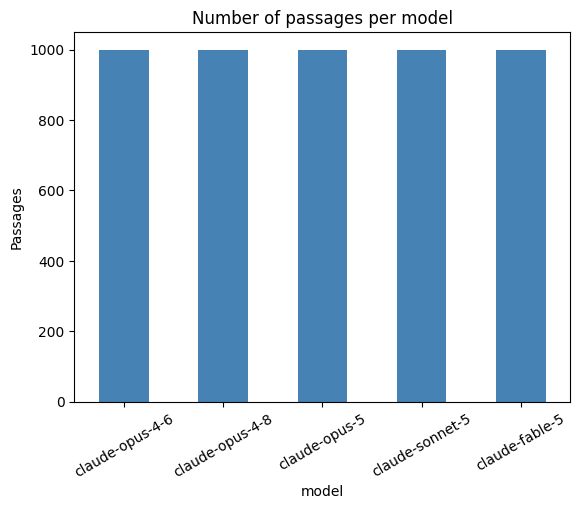

In [89]:
print(df['model'].value_counts())

df['model'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Number of passages per model')
plt.ylabel('Passages')
plt.xticks(rotation=30)
plt.show()

                 n_words  avg_word_len  length_ratio
model                                               
claude-fable-5    117.02          6.55          1.01
claude-opus-4-6   122.70          6.52          1.07
claude-opus-4-8   116.88          6.46          1.03
claude-opus-5     118.61          6.29          1.03
claude-sonnet-5   123.79          6.61          1.09


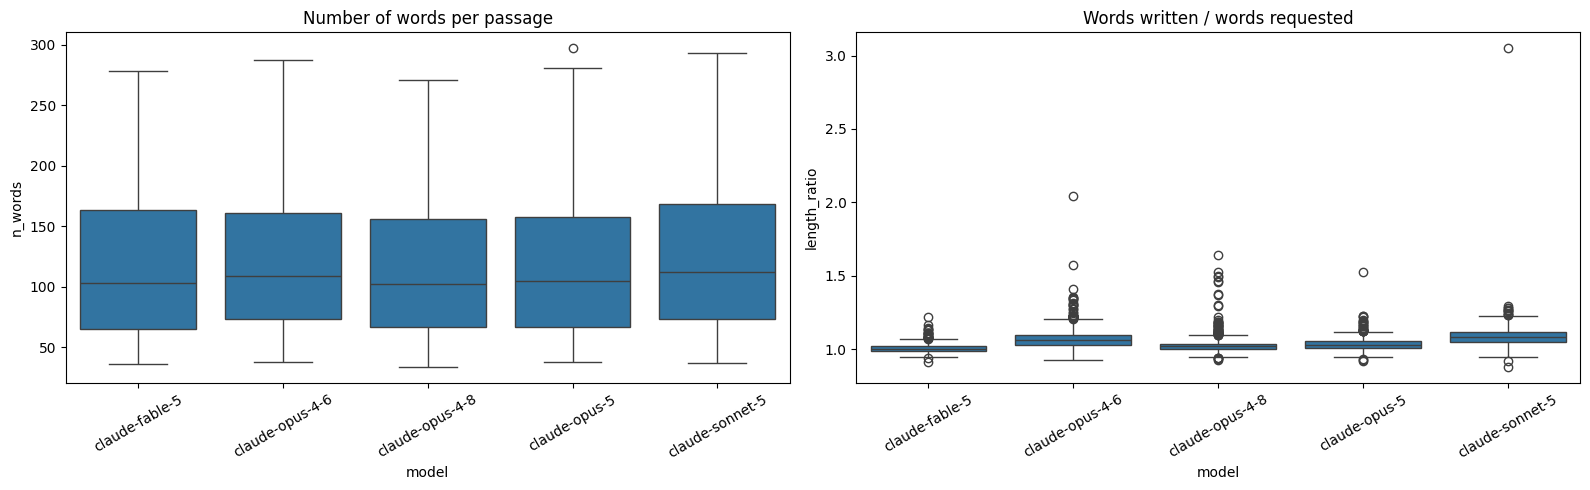

In [90]:
df['n_chars'] = df['text'].str.len()
df['avg_word_len'] = df['n_chars'] / df['n_words']
df['length_ratio'] = df['n_words'] / df['target_words']   # 1.0 = exactly the requested length

print(df.groupby('model')[['n_words', 'avg_word_len', 'length_ratio']].mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df, x='model', y='n_words', ax=axes[0])
axes[0].set_title('Number of words per passage')
sns.boxplot(data=df, x='model', y='length_ratio', ax=axes[1])
axes[1].set_title('Words written / words requested')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [91]:
def top_words(texts, n=10):
    cv = CountVectorizer(stop_words='english')
    counts = cv.fit_transform(texts).sum(axis=0).A1
    return pd.Series(counts, index=cv.get_feature_names_out()).sort_values(ascending=False).head(n)

# Overall
print('Top 20 words overall:')
print(top_words(df['text'], 20))

# Per model
for m in sorted(df['model'].unique()):
    print(f'\n--- {m} ---')
    print(', '.join(top_words(df.loc[df['model'] == m, 'text']).index))

Top 20 words overall:
like       1998
light      1112
water      1014
time        712
earth       692
years       690
world       616
single      614
small       614
air         573
sun         562
roughly     536
surface     523
long        493
beneath     482
way         480
away        467
just        461
people      443
simply      440
dtype: int64

--- claude-fable-5 ---
like, light, water, years, earth, time, small, world, single, sun

--- claude-opus-4-6 ---
like, light, water, earth, time, world, single, small, years, roughly

--- claude-opus-4-8 ---
like, light, water, time, single, world, years, earth, air, sun

--- claude-opus-5 ---
like, light, water, years, roughly, small, air, long, away, world

--- claude-sonnet-5 ---
like, light, water, earth, time, just, small, sun, way, single


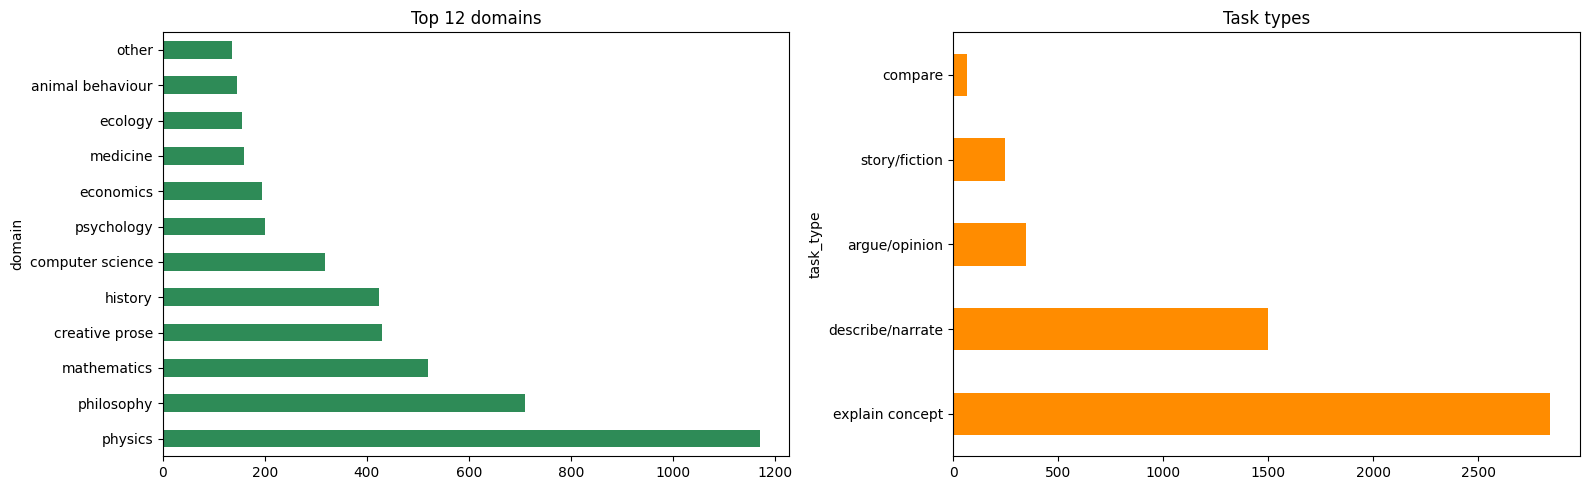

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
df['domain'].value_counts().head(12).plot(kind='barh', ax=axes[0], color='seagreen')
axes[0].set_title('Top 12 domains')
df['task_type'].value_counts().plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Task types')
plt.tight_layout()
plt.show()

In [93]:
def top_words(texts, n=10):
    cv = CountVectorizer(stop_words='english')
    counts = cv.fit_transform(texts).sum(axis=0).A1
    return pd.Series(counts, index=cv.get_feature_names_out()).sort_values(ascending=False).head(n)

for m in sorted(df['model'].unique()):
    print(f'--- {m} ---')
    print(', '.join(top_words(df.loc[df['model'] == m, 'text']).index))

--- claude-fable-5 ---
like, light, water, years, earth, time, small, world, single, sun
--- claude-opus-4-6 ---
like, light, water, earth, time, world, single, small, years, roughly
--- claude-opus-4-8 ---
like, light, water, time, single, world, years, earth, air, sun
--- claude-opus-5 ---
like, light, water, years, roughly, small, air, long, away, world
--- claude-sonnet-5 ---
like, light, water, earth, time, just, small, sun, way, single


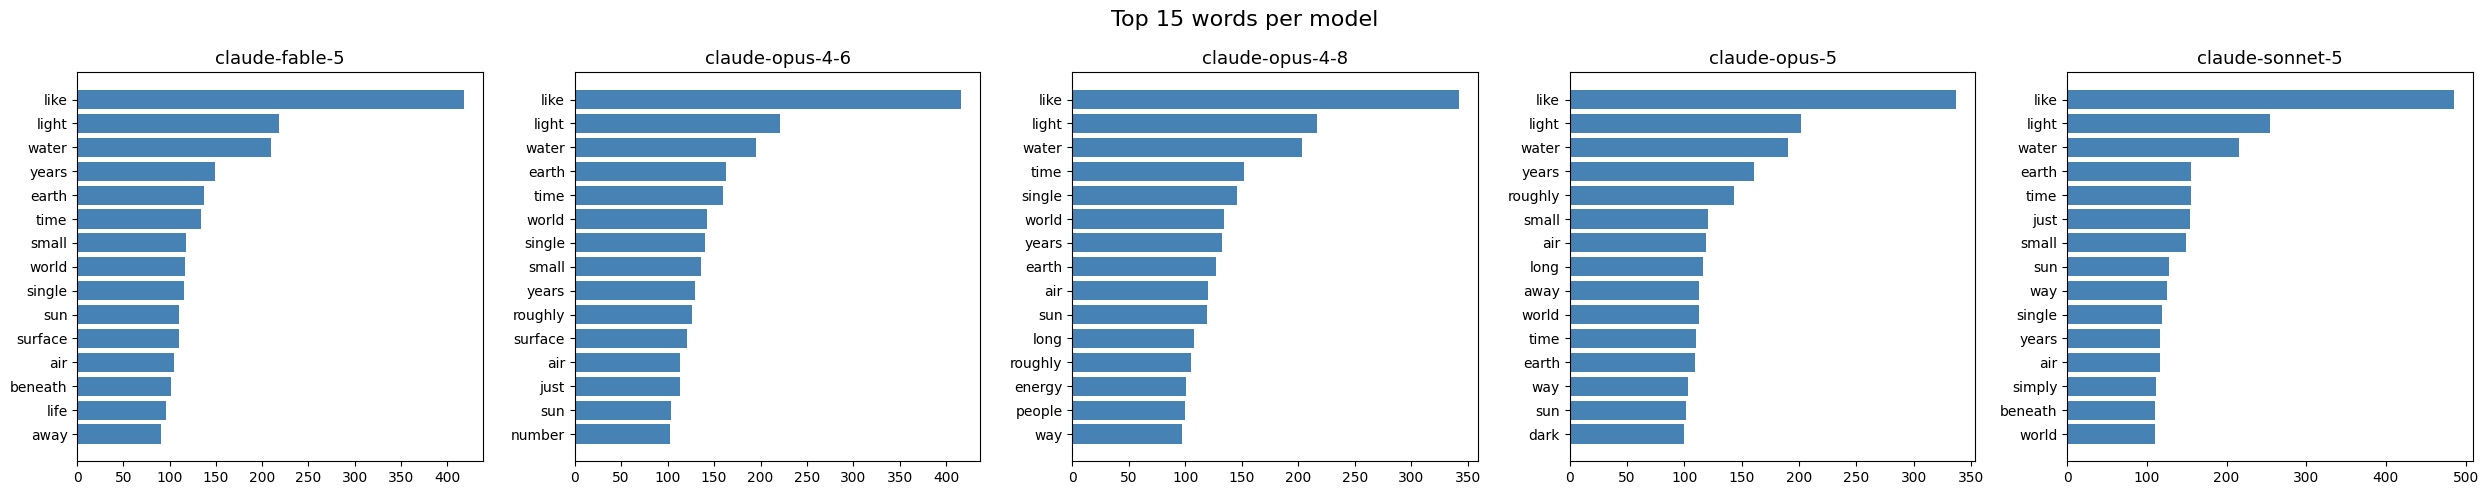

In [94]:
models = sorted(df['model'].unique())
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for ax, m in zip(axes, models):
    cv = CountVectorizer(stop_words='english')
    counts = cv.fit_transform(df.loc[df['model'] == m, 'text']).sum(axis=0).A1
    top = pd.Series(counts, index=cv.get_feature_names_out()).nlargest(15)
    ax.barh(top.index[::-1], top.values[::-1], color='steelblue')
    ax.set_title(m, fontsize=13)
plt.suptitle('Top 15 words per model', fontsize=16)
plt.tight_layout()
plt.show()

In [95]:
example_id = df['prompt_id'].iloc[0]
for _, row in df[df['prompt_id'] == example_id].iterrows():
    print(f"[{row['model']}] ({row['n_words']} words)\n{row['text'][:400]}...\n")

[claude-fable-5] (105 words)
Many people believe that a car's rubber tyres protect them from lightning, but the real reason is the metal body of the vehicle itself. When lightning strikes a car, the metal shell acts as a Faraday cage, conducting the electrical current around the outside of the vehicle and safely into the ground, rather than through the interior where passengers sit. The few centimetres of rubber in the tyres ...

[claude-opus-4-6] (225 words)
Many people believe that during a lightning storm, the rubber tyres on a car act as insulators that prevent the electrical current from reaching the ground, thereby protecting the occupants inside. While this is an understandable assumption, it is actually a misconception. Lightning has already travelled through several kilometres of air, which is itself an excellent insulator, so a few centimetre...

[claude-opus-4-8] (163 words)
It's a common belief that the rubber tyres on your car protect you during a lightning storm by insula

In [96]:
print('Missing values:\n', df.isna().sum())
print('\nDuplicate passages:', df.duplicated('text').sum())
print('Duplicate ids:', df.duplicated('id').sum())

Missing values:
 id              0
prompt_id       0
model           0
text            0
n_words         0
target_words    0
domain          0
task_type       0
topic           0
n_chars         0
avg_word_len    0
length_ratio    0
dtype: int64

Duplicate passages: 0
Duplicate ids: 0


In [97]:
import re

def clean_text(text):
    text = text.lower()                                # 1. lower case
    text = re.sub(r'http\S+|www\.\S+', ' ', text)      # 2. remove URLs
    text = re.sub(r'\d+', ' ', text)                   # 3. remove numbers
    text = re.sub(r'\s+', ' ', text).strip()           # 4. remove extra spaces
    return text

df['clean_text'] = df['text'].apply(clean_text)

print('Passages with URLs:', df['text'].str.contains(r'http|www\.').sum())
print('Passages with numbers:', df['text'].str.contains(r'\d').sum())

Passages with URLs: 0
Passages with numbers: 1645


In [98]:
for mark in ['—', ';', ':', '(', '?', '!']:
    print(repr(mark), df.groupby('model')['text'].apply(lambda s: s.str.count(re.escape(mark)).sum()).to_dict())

'—' {'claude-fable-5': 1249, 'claude-opus-4-6': 1174, 'claude-opus-4-8': 911, 'claude-opus-5': 1304, 'claude-sonnet-5': 1246}
';' {'claude-fable-5': 314, 'claude-opus-4-6': 163, 'claude-opus-4-8': 252, 'claude-opus-5': 542, 'claude-sonnet-5': 251}
':' {'claude-fable-5': 745, 'claude-opus-4-6': 385, 'claude-opus-4-8': 492, 'claude-opus-5': 806, 'claude-sonnet-5': 589}
'(' {'claude-fable-5': 85, 'claude-opus-4-6': 110, 'claude-opus-4-8': 69, 'claude-opus-5': 69, 'claude-sonnet-5': 117}
'?' {'claude-fable-5': 62, 'claude-opus-4-6': 45, 'claude-opus-4-8': 66, 'claude-opus-5': 41, 'claude-sonnet-5': 63}
'!' {'claude-fable-5': 25, 'claude-opus-4-6': 19, 'claude-opus-4-8': 23, 'claude-opus-5': 6, 'claude-sonnet-5': 11}


In [99]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def remove_stop_words(text):
    words = re.findall(r"[a-z']+", text)
    return ' '.join(w for w in words if w not in ENGLISH_STOP_WORDS)

df['no_stop_text'] = df['clean_text'].apply(remove_stop_words)

total = df['clean_text'].str.split().str.len().sum()
after = df['no_stop_text'].str.split().str.len().sum()
print(f'Words before: {total:,}  after: {after:,}  removed: {1 - after/total:.1%}')

Words before: 598,245  after: 336,981  removed: 43.7%


In [100]:
%pip install nltk


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [101]:
import nltk

nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/magamedimamguliev/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/magamedimamguliev/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [102]:
import nltk
nltk.download('wordnet', quiet=True)
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
for word in ['delving', 'conducting', 'strikes', 'acts', 'tyres', 'passengers']:
    print(word, '->', lemmatizer.lemmatize(word, pos='v'), '/', lemmatizer.lemmatize(word))

delving -> delve / delving
conducting -> conduct / conducting
strikes -> strike / strike
acts -> act / act
tyres -> tyres / tyre
passengers -> passengers / passenger


In [103]:
i = 0
print('ORIGINAL:\n', df['text'].iloc[i][:250], '\n')
print('CLEANED (used for the models):\n', df['clean_text'].iloc[i][:250], '\n')
print('WITHOUT STOP WORDS (used for exploration):\n', df['no_stop_text'].iloc[i][:250])

ORIGINAL:
 Many people believe that a car's rubber tyres protect them from lightning, but the real reason is the metal body of the vehicle itself. When lightning strikes a car, the metal shell acts as a Faraday cage, conducting the electrical current around the 

CLEANED (used for the models):
 many people believe that a car's rubber tyres protect them from lightning, but the real reason is the metal body of the vehicle itself. when lightning strikes a car, the metal shell acts as a faraday cage, conducting the electrical current around the 

WITHOUT STOP WORDS (used for exploration):
 people believe car's rubber tyres protect lightning real reason metal body vehicle lightning strikes car metal shell acts faraday cage conducting electrical current outside vehicle safely ground interior passengers sit centimetres rubber tyres offer 


In [104]:
from sklearn.model_selection import GroupShuffleSplit

X = df['clean_text']
y = df['model']
groups = df['prompt_id']

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print('Train passages:', len(X_train), ' Test passages:', len(X_test))
print('Train prompts:', groups_train.nunique(), ' Test prompts:', groups.iloc[test_idx].nunique())
print('Shared prompts:', len(set(groups_train) & set(groups.iloc[test_idx])))
print('\nTrain classes:', y_train.value_counts().to_dict())
print('Test classes: ', y_test.value_counts().to_dict())

Train passages: 4000  Test passages: 998
Train prompts: 800  Test prompts: 200
Shared prompts: 0

Train classes: {'claude-fable-5': 800, 'claude-opus-4-6': 800, 'claude-opus-4-8': 800, 'claude-opus-5': 800, 'claude-sonnet-5': 800}
Test classes:  {'claude-opus-4-6': 200, 'claude-opus-4-8': 200, 'claude-opus-5': 200, 'claude-sonnet-5': 200, 'claude-fable-5': 198}


In [105]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2),   # single words and two-word phrases
                        min_df=2,             # ignore terms found in fewer than 2 passages
                        max_df=0.9,           # ignore terms found in more than 90% of passages
                        max_features=20000,   # keep the 20,000 most frequent terms
                        sublinear_tf=True)    # use 1 + log(TF) instead of raw counts

X_train_tfidf = tfidf.fit_transform(X_train)  # learn vocabulary and IDF from training data only
X_test_tfidf = tfidf.transform(X_test)        # apply the same vocabulary to the test data

In [106]:
print('Train matrix:', X_train_tfidf.shape)
print('Test matrix: ', X_test_tfidf.shape)

feature_names = tfidf.get_feature_names_out()
print('Two-word phrases:', sum(' ' in f for f in feature_names))
print('Average non-zero values per passage:', round(X_train_tfidf.nnz / X_train_tfidf.shape[0], 1))
print('Example features:', feature_names[1000:1015])

# Highest TF-IDF terms of the first training passage
import numpy as np
row = X_train_tfidf[0].toarray()[0]
top = np.argsort(row)[::-1][:10]
print('\nPassage:', X_train.iloc[0][:150], '...')
print([(feature_names[i], round(row[i], 3)) for i in top])

Train matrix: (4000, 20000)
Test matrix:  (998, 20000)
Two-word phrases: 10230
Average non-zero values per passage: 112.2
Example features: ['and touch' 'and trembling' 'and trust' 'and turned' 'and twenty'
 'and two' 'and ultimately' 'and unbroken' 'and understand'
 'and understood' 'and unhurried' 'and unremarkable' 'and used'
 'and vanish' 'and vanished']

Passage: many people believe that a car's rubber tyres protect them from lightning, but the real reason is the metal body of the vehicle itself. when lightning ...
[('tyres', np.float64(0.254)), ('vehicle', np.float64(0.205)), ('metal', np.float64(0.2)), ('the metal', np.float64(0.169)), ('rubber', np.float64(0.167)), ('car', np.float64(0.165)), ('lightning', np.float64(0.151)), ('metal body', np.float64(0.124)), ('outside of', np.float64(0.121)), ('metal shell', np.float64(0.121))]


In [107]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

labels = sorted(y.unique())

def model_report(y_test, y_pred, title=''):
    print('Accuracy:', round(accuracy_score(y_test, y_pred), 3))
    print('Macro F1-score:', round(f1_score(y_test, y_pred, average='macro'), 3))
    print(classification_report(y_test, y_pred, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=labels),
                           display_labels=labels).plot(cmap='Blues', xticks_rotation=30)
    plt.title(title)
    plt.show()

Accuracy: 0.426
Macro F1-score: 0.397
                 precision    recall  f1-score   support

 claude-fable-5       0.39      0.16      0.23       198
claude-opus-4-6       0.43      0.52      0.47       200
claude-opus-4-8       0.43      0.21      0.28       200
  claude-opus-5       0.44      0.73      0.55       200
claude-sonnet-5       0.41      0.51      0.45       200

       accuracy                           0.43       998
      macro avg       0.42      0.43      0.40       998
   weighted avg       0.42      0.43      0.40       998



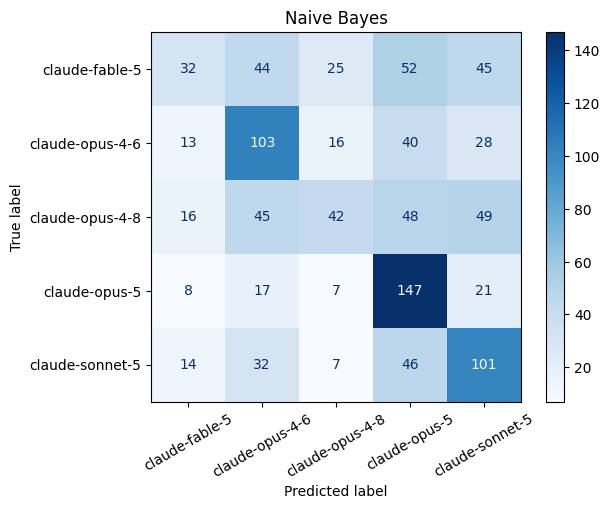

In [109]:
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
nb_pred = nb.predict(X_test_tfidf)
model_report(y_test, nb_pred, 'Naive Bayes')

Accuracy: 0.449
Macro F1-score: 0.445
                 precision    recall  f1-score   support

 claude-fable-5       0.34      0.30      0.32       198
claude-opus-4-6       0.48      0.48      0.48       200
claude-opus-4-8       0.39      0.34      0.36       200
  claude-opus-5       0.57      0.59      0.58       200
claude-sonnet-5       0.45      0.53      0.49       200

       accuracy                           0.45       998
      macro avg       0.44      0.45      0.44       998
   weighted avg       0.44      0.45      0.44       998



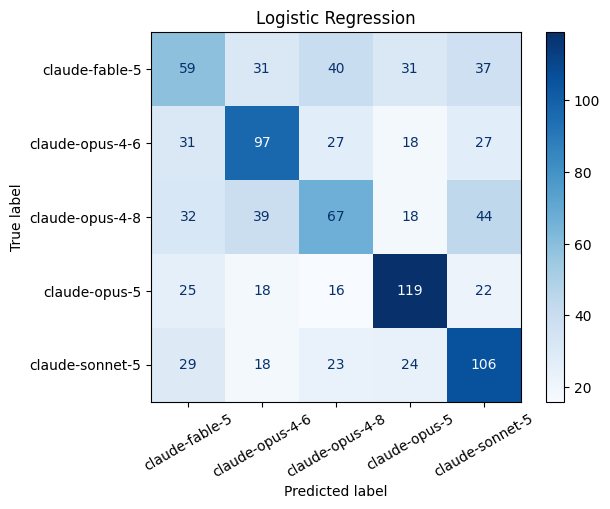

In [110]:
lr = LogisticRegression(max_iter=2000, C=10)
lr.fit(X_train_tfidf, y_train)
lr_pred = lr.predict(X_test_tfidf)
model_report(y_test, lr_pred, 'Logistic Regression')

Accuracy: 0.454
Macro F1-score: 0.441
                 precision    recall  f1-score   support

 claude-fable-5       0.34      0.25      0.29       198
claude-opus-4-6       0.47      0.51      0.49       200
claude-opus-4-8       0.40      0.28      0.33       200
  claude-opus-5       0.53      0.67      0.59       200
claude-sonnet-5       0.47      0.55      0.50       200

       accuracy                           0.45       998
      macro avg       0.44      0.45      0.44       998
   weighted avg       0.44      0.45      0.44       998



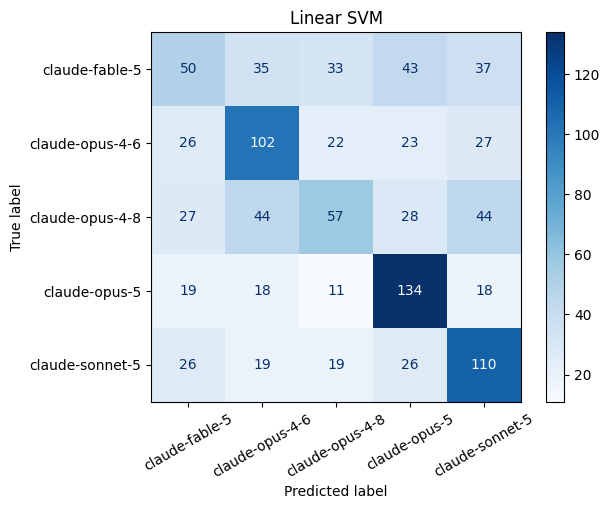

In [111]:
svm = LinearSVC(C=0.5)
svm.fit(X_train_tfidf, y_train)
svm_pred = svm.predict(X_test_tfidf)
model_report(y_test, svm_pred, 'Linear SVM')

In [112]:
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline

gkf = GroupKFold(n_splits=5)

def make_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)

pipelines = {
    'Naive Bayes': Pipeline([('tfidf', make_tfidf()), ('clf', MultinomialNB())]),
    'Logistic Regression': Pipeline([('tfidf', make_tfidf()), ('clf', LogisticRegression(max_iter=2000, C=10))]),
    'Linear SVM': Pipeline([('tfidf', make_tfidf()), ('clf', LinearSVC(C=0.5))]),
}

print('Cross-validation accuracy (5 folds, grouped by prompt)')
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, groups=groups_train, cv=gkf, scoring='accuracy')
    print(f'{name}: {scores.round(3)}  Avg: {scores.mean():.3f}')

Cross-validation accuracy (5 folds, grouped by prompt)
Naive Bayes: [0.382 0.382 0.381 0.361 0.382]  Avg: 0.378
Logistic Regression: [0.429 0.428 0.424 0.41  0.455]  Avg: 0.429
Linear SVM: [0.428 0.414 0.421 0.412 0.446]  Avg: 0.424


Best parameters: {'clf__C': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__stop_words': None, 'tfidf__sublinear_tf': False}
Best CV macro F1: 0.414
Accuracy: 0.45
Macro F1-score: 0.437
                 precision    recall  f1-score   support

 claude-fable-5       0.38      0.25      0.30       198
claude-opus-4-6       0.44      0.48      0.46       200
claude-opus-4-8       0.43      0.29      0.35       200
  claude-opus-5       0.51      0.64      0.57       200
claude-sonnet-5       0.44      0.57      0.50       200

       accuracy                           0.45       998
      macro avg       0.44      0.45      0.44       998
   weighted avg       0.44      0.45      0.44       998



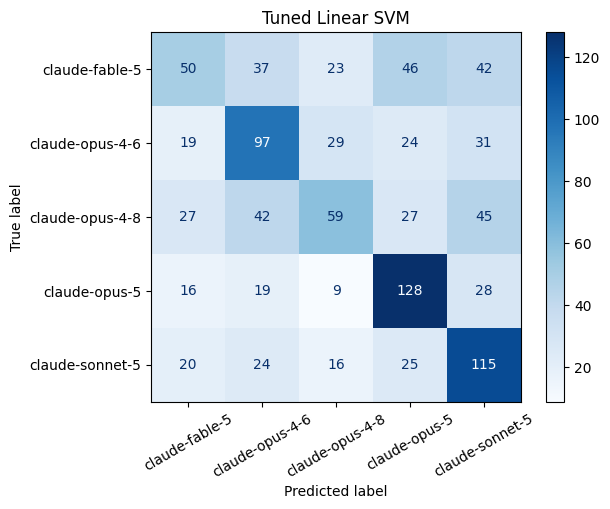

In [113]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__stop_words': [None, 'english'],
    'tfidf__sublinear_tf': [True, False],
    'clf__C': [0.1, 0.5, 1],
}

grid = GridSearchCV(pipelines['Linear SVM'], param_grid, cv=gkf,
                    scoring='f1_macro', n_jobs=-1)
grid.fit(X_train, y_train, groups=groups_train)

print('Best parameters:', grid.best_params_)
print('Best CV macro F1:', round(grid.best_score_, 3))

grid_pred = grid.best_estimator_.predict(X_test)
model_report(y_test, grid_pred, 'Tuned Linear SVM')

In [114]:
results = {'Naive Bayes': nb_pred, 'Logistic Regression': lr_pred,
           'Linear SVM': svm_pred, 'Linear SVM (tuned)': grid_pred}
summary = pd.DataFrame({
    'Accuracy': {k: accuracy_score(y_test, v) for k, v in results.items()},
    'Macro F1': {k: f1_score(y_test, v, average='macro') for k, v in results.items()},
}).round(3).sort_values('Macro F1', ascending=False)
summary

,Accuracy,Macro F1
Logistic Regression,0.449,0.445
Linear SVM,0.454,0.441
Linear SVM (tuned),0.450,0.437
Naive Bayes,0.426,0.397
